In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k = 1.0
A, B = 2, 2
u = lambda t,x,y: -y**2
v = lambda t,x,y: 0.0
u_x = lambda t,x,y: np.zeros_like(x)
u_y = lambda t,x,y: -2*y
v_x = lambda t,x,y: np.zeros_like(x)
v_y = lambda t,x,y: np.zeros_like(x)

In [2]:


def dphi_dt(t, x, y, phi):
    return (v_x(t, x, y)*np.sin(phi)**2
            + (u_x(t, x, y) - v_y(t, x, y))*np.sin(phi)*np.cos(phi)
            - u_y(t, x, y)*np.cos(phi)**2)

def solve_one(phi0, T, n_pts=200):
    x0, y0 = 0, 0
    def func(t, w):
        x, y, phi = w
        return [u(t, x, y) + k*np.cos(phi),
                v(t, x, y) + k*np.sin(phi),
                dphi_dt(t, x, y, phi)]
    res = solve_ivp(func, (0, T), [x0, y0, phi0],
                    t_eval=np.linspace(0, T, n_pts), atol=1e-8, rtol=1e-8)
    x, y, phi = res.y
    return x, y
    
def iterate(range_phi0, range_T):
    losses = np.zeros((len(range_phi0), len(range_T)))
    xvals = np.empty((len(range_phi0), len(range_T)), dtype=object)
    yvals = np.empty((len(range_phi0), len(range_T)), dtype=object)
    for i,phi0 in enumerate(range_phi0):
        for j,T in enumerate(range_T):
            x,y = solve_one(phi0, T)
            loss = np.linalg.norm([x[-1]-A, y[-1]-B])
            xvals[i,j] = x
            yvals[i,j] = y
            losses[i,j] = loss
    return losses, xvals, yvals

def deepen(num, phi_init, T_init, h_phi0=1e-7, h_T=1e-7, pct_increase_stop=0.001, lmbda=0.5):
    trajectory = np.empty((num, 2), dtype=object) # x, y
    losses = np.empty(num, dtype=float)
    params = np.empty((num, 2), dtype=object)

    phi, T = phi_init, T_init
    c = 0
    pct = 1.0

    while c < num and pct >= pct_increase_stop:
        x, y = solve_one(phi, T)
        trajectory[c, 0] = x
        trajectory[c, 1] = y
        params[c, 0] = phi
        params[c, 1] = T
        r = np.array([x[-1] - A, y[-1] - B])
        losses[c] = np.linalg.norm(r)

        xp, yp = solve_one(phi + h_phi0, T)
        r_phi = np.array([xp[-1] - A, yp[-1] - B])
        xt, yt = solve_one(phi, T + h_T)
        r_T = np.array([xt[-1] - A, yt[-1] - B])

        J = np.column_stack([(r_phi - r) / h_phi0, (r_T - r) / h_T])
        delta = -np.linalg.pinv(J) @ r            # Newton step in (phi, T)
        phi, T = phi + lmbda * delta[0], max(T + lmbda * delta[1], 1e-3)

        pct = np.linalg.norm(delta) / max(np.linalg.norm([phi, T]), 1e-12)
        c += 1

    return trajectory, losses, params, c

params: [[0.5 np.float64(2.8284271247461903)]
 [np.float64(-0.6315056525208647) np.float64(4.146681974046347)]
 [np.float64(-25.635052261579737) 0.001]
 [np.float64(1332.2896144713739) np.float64(0.39551960766738087)]
 [np.float64(1333.910186146816) np.float64(1.4548510262519045)]
 [np.float64(1333.30428067008) np.float64(1.0559834323253867)]
 [np.float64(1331.6026722454956) np.float64(1.990408088995344)]
 [np.float64(1330.5017204799633) 0.001]
 [np.float64(2367.0304703489714) 0.001]
 [np.float64(3195.4050376799137) 0.001]]
phistar, Tstar: 3195.4050376799137 0.001
best time: 0.001


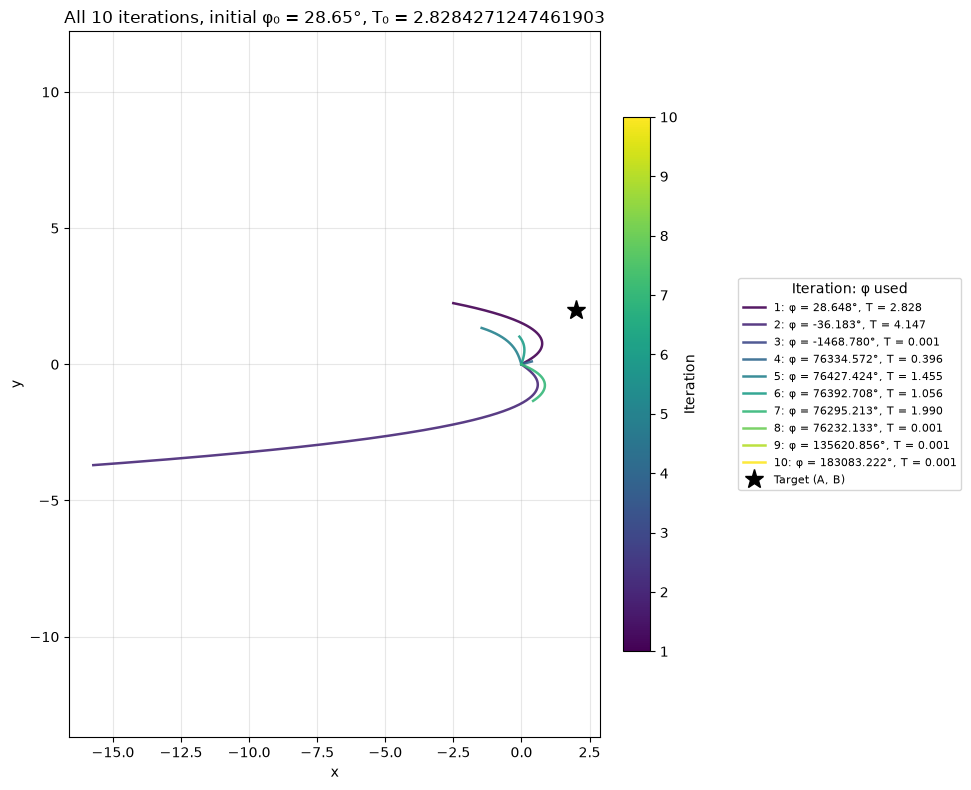

In [3]:
from matplotlib import cm, colors

phi0 = 0.5 # 57 deg

T0 = np.hypot(A, B) # initial guess for final time

trajectory, losses, params, num_iters = deepen(
    num=10, phi_init=phi0, T_init=T0
)

print('params:', params)

Tstar = params[num_iters-1, 1]
phistar = params[num_iters-1, 0] # best ones according to algo
x_best, y_best = trajectory[-1]
#phi_best = np.atan2(y_best / x_best) if x_best != 0 else np.pi / 2
fig, ax = plt.subplots(figsize=(10, 8))

print('phistar, Tstar:', phistar, Tstar)
print('best time:', Tstar)

cmap = cm.viridis
norm = colors.Normalize(vmin=1, vmax=max(num_iters, 2))

# every iteration, colored by its iteration number and labelled with its phi
k = 0
"""

ax.plot(x, y, color=cmap(norm(k + 1)), lw=1.8, alpha=0.9,
                label=f"{k + 1}: φ = {180/np.pi*phi:.3f}°, T = {T:.3f}")
        k += 1
        """
for k in range(num_iters):
    x, y = trajectory[k]
    phi_k, T_k = params[k, :]
    ax.plot(x, y, color=cmap(norm(k + 1)), lw=1.8, alpha=0.9,
            label=f"{k + 1}: φ = {180/np.pi*phi_k:.3f}°, T = {T_k:.3f}")

        

# start point and target
#ax.plot(paths[0][0][0], paths[0][1][0], "go", markersize=8, label="Start")
ax.plot(A, B, "k*", markersize=14, label="Target (A, B)")

# colorbar for the iteration number
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, label="Iteration", fraction=0.046, pad=0.04)

ax.set_title(f"All {num_iters} iterations, initial φ₀ = {180/np.pi*phi0:.2f}°, T₀ = {T0}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

# legend outside the axes, to the right of the colorbar
ax.legend(title="Iteration: φ used", loc="center left",
          bbox_to_anchor=(1.25, 0.5), fontsize=8)

"""
TEMP: COMPARE TO OPTIMAL
"""
# t = np.linspace(0, Tstar, 200)
# phi_best = np.arctan(t+np.tan(phistar))
# y_best = 1/np.cos(phi_best)-1/np.cos(phistar)

# def x_of_y(y, x):
#        s = 1/np.cos(phistar)
#        return (1 - y*(y + s)) / np.sqrt((y + s)**2 - 1)

# sol_x = solve_ivp(x_of_y, (0, y_best[-1]), [0], t_eval=y_best)
# x_best = sol_x.y[0]

# ax.plot(x_best, y_best, "k--", lw=1.8, label="Optimal path (solve_ivp in y)")

# # legend outside the axes, to the right of the colorbar
# ax.legend(title="Iteration: φ used", loc="center left",
#           bbox_to_anchor=(1.25, 0.5), fontsize=8)

"""
ENDTEMP
"""

fig.tight_layout()
plt.show()